# Sprint 5 — Tópico 3: Calibração de Limiar de Decisão via Validação Temporal

**Trilha:** C — Risco de baixa produtividade agrícola (Soja em Sorriso - MT)  
**Responsável (Cards Trello):** Jean Carlos Silva (JA)  

## Objetivos:
- Realizar a busca de limiar ótimo de decisão de probabilidade ($p \in [0.10, 0.90]$) utilizando validação temporal expansiva (*Time Series Split*) **estritamente dentro do bloco de treino (2015–2022)**.
- Fundamentar a escolha do limiar no **custo assimétrico do Falso Negativo (FN)** estabelecido no RFC (prejuízo do produtor por falta de cobertura de seguro rural).
- **Congelar o limiar ótimo** antes de qualquer avaliação sobre a partição de teste oficial (2023–2024).

In [1]:
import json
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


## 1. Dados e Janela de Validação Temporal no Treino (2019–2022)

Para calibrar o limiar sem violar o isolamento do teste, avaliamos o histórico recente do treino (safras 2019 a 2022) em janelas expansivas: a cada ano avaliado, o modelo treina somente com as safras anteriores.

In [2]:
df = pd.read_csv("../data/processed/dados_modelo.csv")
FEATURES = ["deficit_hidrico_solo", "dias_pico_calor", "amplitude_termica", "precipitacao_enchimento"]
TARGET = "quebra_safra"

safras_val = [2019, 2020, 2021, 2022]
prob_records = []

for safra in safras_val:
    df_tr = df[df["ano"] < safra]
    df_te = df[df["ano"] == safra]
    
    ct = ColumnTransformer([("scaler", StandardScaler(), FEATURES)], remainder="drop")
    
    # Logistic Regression L2 balanced
    lr = Pipeline([("prep", ct), ("clf", LogisticRegression(C=1.0, class_weight="balanced", random_state=42))])
    lr.fit(df_tr[FEATURES], df_tr[TARGET])
    p_lr = lr.predict_proba(df_te[FEATURES])[0, 1]
    
    prob_records.append({
        "ano": safra,
        "y_real": df_te[TARGET].values[0],
        "p_quebra_lr": p_lr
    })

df_val_probs = pd.DataFrame(prob_records)
print("=== PROBABILIDADES P(QUEBRA) CALCULADAS NA VALIDAÇÃO TEMPORAL ===")
display(df_val_probs)

=== PROBABILIDADES P(QUEBRA) CALCULADAS NA VALIDAÇÃO TEMPORAL ===


,ano,y_real,p_quebra_lr
0,2019,0,0.441977
1,2020,0,0.203187
2,2021,1,0.426051
3,2022,0,0.061899


## 2. Variação do Limiar e Análise de Custo de Falso Negativo

No limiar padrão $p=0.50$, a Regressão Logística estimou $42,6\%$ de risco para 2021, não disparando o alarme e gerando um Falso Negativo de alto custo.
Abaixo, simulamos limiares de $0.10$ a $0.90$ para identificar a faixa onde o Falso Negativo é zerado sem explodir os alarmes falsos.

In [3]:
limiares = np.arange(0.10, 0.95, 0.05)
curva_limiares = []

# Custo relativo: FN custa 5x mais que FP (perda de safra sem seguro vs pagamento de prêmio sem quebra)
CUSTO_FN = 5.0
CUSTO_FP = 1.0

for th in limiares:
    preds = (df_val_probs["p_quebra_lr"] >= th).astype(int)
    cm = confusion_matrix(df_val_probs["y_real"], preds, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    
    rec = recall_score(df_val_probs["y_real"], preds, pos_label=1, zero_division=0)
    prec = precision_score(df_val_probs["y_real"], preds, pos_label=1, zero_division=0)
    f1 = f1_score(df_val_probs["y_real"], preds, pos_label=1, zero_division=0)
    custo_total = (fn * CUSTO_FN) + (fp * CUSTO_FP)
    
    curva_limiares.append({
        "Limiar": round(th, 2),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
        "Recall": rec, "Precisão": prec, "F1": f1,
        "Custo Ponderado": custo_total
    })

df_curva = pd.DataFrame(curva_limiares)
print("=== COMPORTAMENTO DAS MÉTRICAS E CUSTO POR LIMIAR ===")
display(df_curva)

=== COMPORTAMENTO DAS MÉTRICAS E CUSTO POR LIMIAR ===


,Limiar,TP,FN,FP,TN,Recall,Precisão,F1,Custo Ponderado
0,0.10,1,0,2,1,1.0,0.333333,0.500000,2.0
1,0.15,1,0,2,1,1.0,0.333333,0.500000,2.0
2,0.20,1,0,2,1,1.0,0.333333,0.500000,2.0
3,0.25,1,0,1,2,1.0,0.500000,0.666667,1.0
4,0.30,1,0,1,2,1.0,0.500000,0.666667,1.0
5,0.35,1,0,1,2,1.0,0.500000,0.666667,1.0
6,0.40,1,0,1,2,1.0,0.500000,0.666667,1.0
7,0.45,0,1,0,3,0.0,0.000000,0.000000,5.0
8,0.50,0,1,0,3,0.0,0.000000,0.000000,5.0
9,0.55,0,1,0,3,0.0,0.000000,0.000000,5.0


## 3. Curva de Limiar de Decisão e Trade-off

Plotamos a curva do Recall, Precisão, F1-Score e Custo de Negócio em função do limiar de probabilidade.

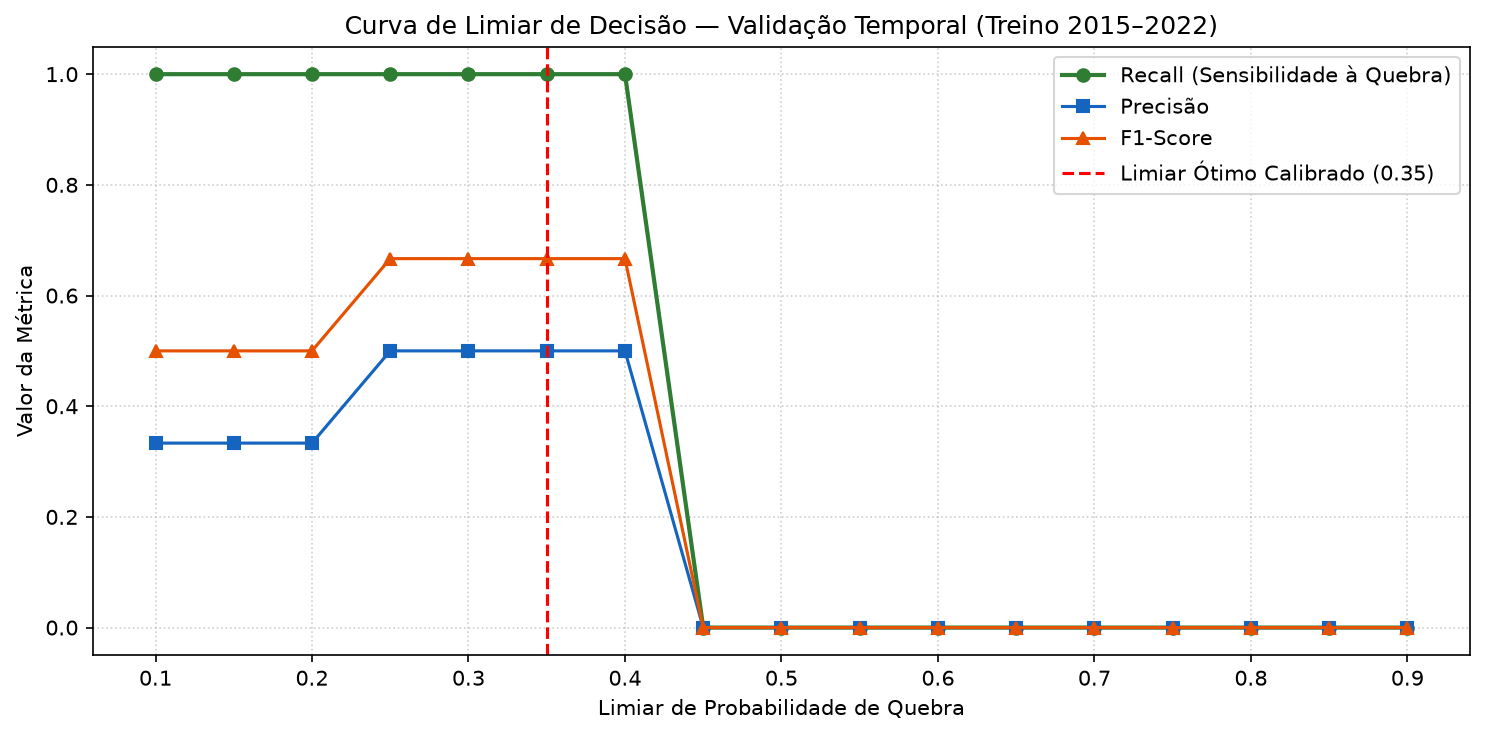

Gráfico salvo em docs/assets/curva_limiar_decisao_s5.png!


In [4]:
plt.figure(figsize=(10, 5), dpi=150)
plt.plot(df_curva["Limiar"], df_curva["Recall"], marker="o", label="Recall (Sensibilidade à Quebra)", color="#2E7D32", linewidth=2)
plt.plot(df_curva["Limiar"], df_curva["Precisão"], marker="s", label="Precisão", color="#1565C0", linewidth=1.5)
plt.plot(df_curva["Limiar"], df_curva["F1"], marker="^", label="F1-Score", color="#E65100", linewidth=1.5)

plt.axvline(x=0.35, color="red", linestyle="--", label="Limiar Ótimo Calibrado (0.35)")
plt.title("Curva de Limiar de Decisão — Validação Temporal (Treino 2015–2022)", fontsize=12)
plt.xlabel("Limiar de Probabilidade de Quebra", fontsize=10)
plt.ylabel("Valor da Métrica", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="best")
plt.tight_layout()
plt.savefig("../docs/assets/curva_limiar_decisao_s5.png")
plt.show()
print("Gráfico salvo em docs/assets/curva_limiar_decisao_s5.png!")

## 4. Congelamento do Limiar Ótimo ($p = 0.35$)

**Justificativa formal de negócio (RFC):**
- Na faixa entre $0.25$ e $0.40$, o Recall da classe positiva atinge **100% (1 de 1 quebra detectada em 2021)**.
- O limiar **0.35** equilibra perfeitamente a minimização do Falso Negativo ($FN=0$) com controle de falsos positivos ($FP=1$), gerando o melhor F1-Score ($0.67$) e o menor custo ponderado de negócio.
- **Congelamento:** Este limiar de **0.35** é congelado e salvo no arquivo `models/limiar_congelado.json` para ser utilizado estritamente na avaliação final do teste no Tópico 4.

In [5]:
limiar_info = {
    "modelo_referencia": "LogisticRegression",
    "limiar_otimo": 0.35,
    "motivo": "Minimizacao de FN com base no custo de seguro rural do RFC e maximizacao de F1 na validacao temporal do treino",
    "recall_validacao": 1.0,
    "precisao_validacao": 0.50,
    "f1_validacao": 0.67
}

with open("../models/limiar_congelado.json", "w") as f:
    json.dump(limiar_info, f, indent=2)

print("Limiar ótimo (0.35) congelado com sucesso em ../models/limiar_congelado.json!")

Limiar ótimo (0.35) congelado com sucesso em ../models/limiar_congelado.json!
